In [2]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold,GridSearchCV)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from scipy.interpolate import interp1d


In [68]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_13.pkl',
         'E3_MB07_Day09High_18.pkl', 
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
         'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
         'E3_MB07_Day09High_4.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


# SPIKE MODEL

## best code

## with those models

Session Day01: starting (neurons=15)
Session Day01: kept 15 significant neurons
Session Day03: starting (neurons=11)
Session Day03: kept 5 significant neurons
Session Day04: starting (neurons=15)
Session Day04: kept 9 significant neurons
Session Day05: starting (neurons=15)
Session Day05: kept 12 significant neurons
Session Day06: starting (neurons=12)
Session Day06: kept 7 significant neurons
Session Day07: starting (neurons=17)
Session Day07: kept 6 significant neurons
Session Day08: starting (neurons=14)
Session Day08: kept 9 significant neurons
Session Day09: starting (neurons=17)
Session Day09: kept 11 significant neurons
Session Day10: starting (neurons=16)
Session Day10: kept 10 significant neurons
Session Day11: starting (neurons=14)
Session Day11: kept 6 significant neurons
Session Day12: starting (neurons=15)
Session Day12: kept 8 significant neurons
Session Day13: starting (neurons=15)
Session Day13: kept 9 significant neurons
Session Day14: starting (neurons=12)
Session Day

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_68883/2983444226.py:195: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)


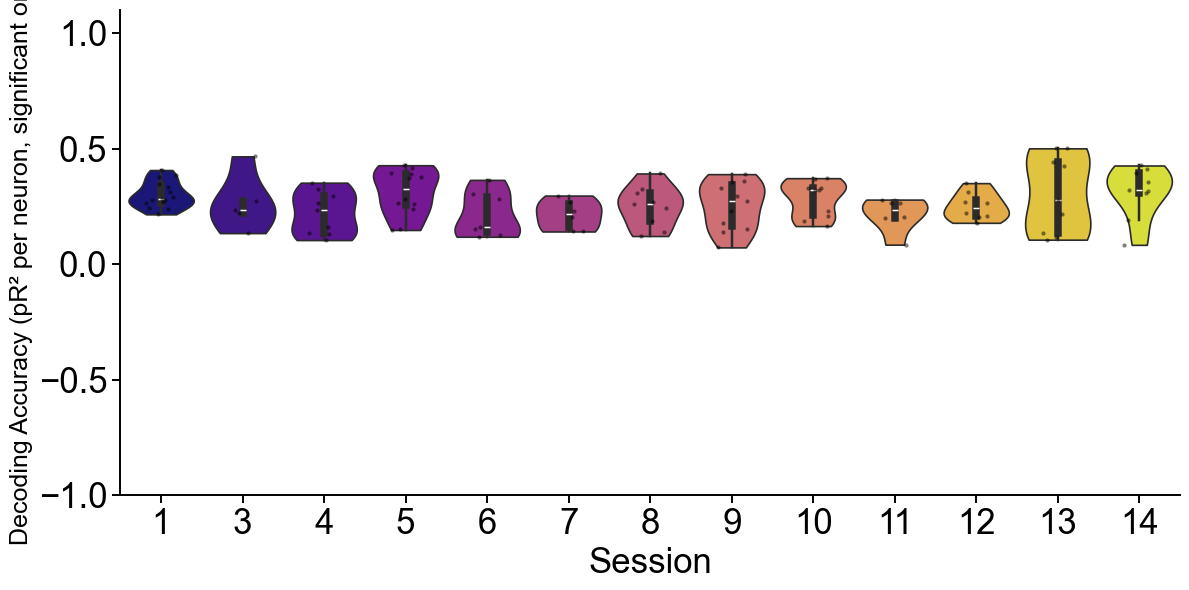

Saved summary violin: /Users/nmt121/Desktop/GLM_spikes_pR2_violin_SIGONLY_perNEURON_bin100ms.pdf


In [109]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, re, os

# --------- config ---------
folder_path = '/Users/nmt121/Desktop/DATA/S1/'
session_files = session_files1
bin_size_ms = 100
fsamp = 2048
min_total_spikes_per_fold = 10
n_splits_cv = 10
save_dir = '/Users/nmt121/Desktop/'
example_dir = os.path.join(save_dir, 'examples'); os.makedirs(example_dir, exist_ok=True)

# --------- helpers ---------
def choose_target_mass(y):
    p = np.mean(np.asarray(y) > 0)
    if p < 0.01: tm0, tm1, tm2 = 0.5, 30.0, 15.0
    elif p < 0.03: tm0, tm1, tm2 = 0.5, 20.0, 10.0
    elif p < 0.06: tm0, tm1, tm2 = 0.7, 14.0, 7.0
    else: tm0, tm1, tm2 = 1.0, 8.0, 4.0
    return (tm0, tm1, tm2)

def make_weights(y, cap=200.0, normalize=True):
    y = np.asarray(y).astype(int)
    tm0, tm1, tm2 = choose_target_mass(y)
    n0 = int((y == 0).sum()); n1 = int((y == 1).sum()); n2 = int((y == 2).sum())
    w0 = tm0 / max(n0, 1); w1 = tm1 / max(n1, 1) if n1 > 0 else cap; w2 = tm2 / max(n2, 1) if n2 > 0 else cap
    w = np.ones_like(y, float)
    w[y == 0] = np.clip(w0, 1.0 / cap, cap)
    w[y == 1] = np.clip(w1, 1.0 / cap, cap)
    w[y == 2] = np.clip(w2, 1.0 / cap, cap)
    if normalize:
        s = float(w.sum())
        if s > 0 and np.isfinite(s): w *= (len(w) / s)
    return w

def _ll_poisson(y, lam):
    lam = np.clip(np.asarray(lam, float), 1e-12, None)
    y = np.asarray(y, float)
    return float(np.sum(y * np.log(lam) - lam))

def compute_pR2(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    mu  = np.clip(np.asarray(y_pred, float), 1e-12, None)
    mu0 = np.full_like(y_true, max(y_true.mean(), 1e-12))
    ll_m  = _ll_poisson(y_true, mu)
    ll_0  = _ll_poisson(y_true, mu0)
    ll_sat = _ll_poisson(y_true, np.clip(y_true, 1e-12, None))
    denom = ll_sat - ll_0
    return np.nan if (not np.isfinite(denom) or denom <= 0) else float(np.clip((ll_m - ll_0) / denom, -1.0, 1.0))

def extract_day_label(s):
    m = re.search(r'(\d+)', s)
    return str(int(m.group(1))) if m else s

def build_trial_groups(trial_data_list):
    groups = []
    for t_idx, arr in enumerate(trial_data_list):
        T = int(arr.shape[1])
        groups.append(np.full(T, t_idx, dtype=int))
    return np.concatenate(groups, axis=0)

def bootstrap_ci_vector(y_true, y_pred, n_iter=500, alpha=0.05, rng=0):
    rng = np.random.default_rng(rng)
    T = len(y_true)
    pr2_samples = np.empty(n_iter, dtype=float)
    for k in range(n_iter):
        idx = rng.integers(0, T, T)
        pr2_samples[k] = compute_pR2(y_true[idx], y_pred[idx])
    lo = float(np.nanpercentile(pr2_samples, 100.0 * (alpha / 2.0)))
    hi = float(np.nanpercentile(pr2_samples, 100.0 * (1.0 - alpha / 2.0)))
    return float(np.nanmean(pr2_samples)), lo, hi

# --------- MAIN (HGB only) ---------
session_sig_pr2 = {}

for session, pkl_files in session_files.items():
    # load & stack trials
    trial_data_list = []
    for file in pkl_files:
        glm_data, data, mnpair = load_and_preprocess(file, folder_path, bin_size_ms, fsamp)
        trial_data_list.append(glm_data.T)  # (neurons, timebins)
    if len(trial_data_list) == 0: continue

    concatenated = np.hstack(trial_data_list)   # (neurons, total_timebins)
    num_neurons = int(concatenated.shape[0])
    groups_time = build_trial_groups(trial_data_list)
    if groups_time.shape[0] != concatenated.shape[1]:
        raise RuntimeError("groups vs timebins mismatch")

    outer_kf = GroupKFold(n_splits=min(n_splits_cv, len(np.unique(groups_time))))
    session_sig_pr2[session] = []
    print(f"Session {session}: starting (neurons={num_neurons})")

    for target_idx in range(num_neurons):
        X, Y = create_glm_data(concatenated.T, target_idx)
        if X is None or Y is None: continue

        # drop NaNs/inf and align groups
        if (not np.all(np.isfinite(X))) or (not np.all(np.isfinite(Y))):
            good = np.isfinite(Y)
            for j in range(X.shape[1]): good &= np.isfinite(X[:, j])
            X, Y = X[good], Y[good]
            grp = groups_time[good]
        else:
            grp = groups_time

        if np.sum(Y) < min_total_spikes_per_fold: continue

        # aggregate LL across folds to produce ONE neuron-level pR²
        ll_m_sum = 0.0; ll_sat_sum = 0.0; total_y = 0.0; total_n = 0
        y_true_all, y_pred_all = [], []
        fold_i = 0

        for train_idx, test_idx in outer_kf.split(X, Y, groups=grp):
            fold_i += 1
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]
            if np.sum(Y_test) < min_total_spikes_per_fold: continue

            # weights + light clip to avoid single-bin domination
            w_train = make_weights(Y_train, cap=200.0, normalize=True)
            Y_train_clipped = np.minimum(Y_train, 5)

            # ---- single model: HGB with Poisson loss ----
            mdl = HistGradientBoostingRegressor(
                loss="poisson",
                learning_rate=0.04,
                max_iter=2000,
                max_depth=3,
                min_samples_leaf=30,
                l2_regularization=0.1,
                early_stopping=True,
                validation_fraction=0.1,
                random_state=42
            )
            mdl.fit(X_train, Y_train_clipped, sample_weight=w_train)
            y_pred = np.clip(mdl.predict(X_test), 1e-12, None)

            # accumulate for neuron-level pR²
            ll_m_sum  += _ll_poisson(Y_test, y_pred)
            ll_sat_sum += _ll_poisson(Y_test, np.clip(Y_test, 1e-12, None))
            total_y   += float(Y_test.sum())
            total_n   += int(Y_test.shape[0])
            y_true_all.append(Y_test); y_pred_all.append(y_pred)

            # example plot
            if target_idx == 1 and session == list(session_files.keys())[0]:
                plt.figure(figsize=(12,4))
                plt.plot(Y_test, label="True spikes (binned)", color="black")
                plt.plot(y_pred, label="Predicted intensity", color="red")
                plt.xlabel("Time bins"); plt.ylabel("Spike count")
                plt.title(f"Neuron {target_idx} | Session {session} | Fold {fold_i}")
                plt.legend(); plt.tight_layout()
                plt.savefig(os.path.join(example_dir, f"{session}_neuron{target_idx}_fold{fold_i}_bin{bin_size_ms}ms.pdf"),
                            dpi=300, bbox_inches='tight')
                plt.close()

        if total_n == 0: continue
        mu0 = max(total_y / total_n, 1e-12)
        ll0_total = total_y * np.log(mu0) - total_n * mu0
        denom = ll_sat_sum - ll0_total
        pr2_neuron = np.nan if (not np.isfinite(denom) or denom <= 0) else float(np.clip((ll_m_sum - ll0_total) / denom, -1.0, 1.0))

        # bootstrap CI on concatenated predictions
        y_true_cat = np.concatenate(y_true_all, axis=0)
        y_pred_cat = np.concatenate(y_pred_all, axis=0)
        pr2_mean, pr2_lo, pr2_hi = bootstrap_ci_vector(y_true_cat, y_pred_cat, n_iter=500, alpha=0.05, rng=123 + target_idx)

        if pr2_lo > 0:
            session_sig_pr2[session].append(pr2_neuron)

    print(f"Session {session}: kept {len(session_sig_pr2[session])} significant neurons")

# --------- violin: significant neurons only ---------
plt.figure(figsize=(12,6)); plt.rcParams.update({'font.family':'Arial'})
all_pR2s, all_labels = [], []
for session, vals in session_sig_pr2.items():
    if len(vals) == 0: continue
    lab = extract_day_label(session)
    all_pR2s.extend(vals); all_labels.extend([lab]*len(vals))

if len(all_pR2s) == 0:
    print("No significant neurons found (CI lower bound ≤ 0).")
    all_pR2s = [0.0]; all_labels = ["none"]

unique_sessions = sorted(set(all_labels), key=lambda x: int(x)) if all_labels != ["none"] else ["none"]
N = max(2, len(unique_sessions))
cmap = plt.get_cmap('plasma')
colors = [cmap(i/(N-1)) for i in range(N)]
palette_dict = dict(zip(unique_sessions, colors))

sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)
ax = plt.gca()
for s in ax.spines.values(): s.set_linewidth(1.4)
plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR² per neuron, significant only)", fontsize=18, fontname="Arial")
plt.ylim([-1, 1.1]); sns.despine(top=True, right=True); plt.tight_layout()
summary_path = os.path.join(save_dir, f"GLM_spikes_pR2_violin_SIGONLY_perNEURON_bin{bin_size_ms}ms.pdf")
plt.savefig(summary_path, dpi=300, bbox_inches='tight')
plt.show()
print("Saved summary violin:", summary_path)


# FORCE MODEL

In [ ]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_force_pred import *

# === Input parameters ===
folder_path = '/Users/nmt121/Desktop/DATA/S7/'
bin_size_ms = 200  
session_files = session_files7

#regularization 
alpha_grid = {'poissonregressor__alpha': [0.1, 1, 10, 100, 1000]}  
session_results = {}

#init cross val
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)


def preprocess_trial_force(file, folder_path, bin_size_ms, fsamp=2048):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()
        
    data_MU = np.array(data['MU'].tolist())

    # Convert bin size from ms to samples
    bin_size_samples = int(bin_size_ms * fsamp / 1000)

    # Determine number of bins
    num_timepoints = force.shape[0]
    num_bins = num_timepoints // bin_size_samples

    # Bin the spikes and force
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_samples, bin_size_samples), axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_samples], np.arange(0, num_bins * bin_size_samples, bin_size_samples)) / bin_size_samples

    mnpair = data['Idx_MU_Pair'].tolist()

    return binned_spikes, binned_force, mnpair


# === MAIN EXECUTION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []
    force_trials = []
    spike_trials = []

    for file in pkl_files:
        spikes, force, mnpair = preprocess_trial_force(file,folder_path, bin_size_ms)
        if spikes is None or force is None:
            continue
        force_trials.append(force)
        spike_trials.append(spikes)

    if not force_trials or not spike_trials:
        continue

    concatenated_force = np.concatenate(force_trials)
    concatenated_spikes = np.hstack(spike_trials)
    num_neurons = concatenated_spikes.shape[0]

    for neuron_idx in range(num_neurons):
        
        if neuron_idx: #== mnpair[0] : #or target_idx == mnpair[1]:

            neuron_spikes = concatenated_spikes[neuron_idx, :]

            X, Y = create_force_glm_data(concatenated_force, neuron_spikes)
            if X is None or Y is None or np.sum(Y) < 20:
                continue

            # === Inner CV for alpha ===
            pipeline = make_pipeline(StandardScaler(), PoissonRegressor(max_iter=1000))
            inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(pipeline, alpha_grid, cv=inner_kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X, Y)
            best_alpha = poisson_cv.best_params_['poissonregressor__alpha']

            # === Outer CV for model performance ===
            fold_pR2s = []
            for train_idx, test_idx in outer_kf.split(X):
                X_train, X_test = X[train_idx], X[test_idx]
                Y_train, Y_test = Y[train_idx], Y[test_idx]

                if np.sum(Y_test) < 5:
                    continue

                scaler = StandardScaler()
                X_train_scaled = scaler.fit_transform(X_train)
                X_test_scaled = scaler.transform(X_test)

                model = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                model.fit(X_train_scaled, Y_train)

                pR2 = compute_pR2(model, X_test_scaled, Y_test)
                fold_pR2s.append(pR2)

            if fold_pR2s:
                mean_pR2 = np.nanmean(fold_pR2s)
                session_pR2.append(mean_pR2)

    if session_pR2:
        session_results[session] = session_pR2

# # === PLOTTING RESULTS ===

plt.figure(figsize=(12, 6))
plt.rcParams.update({'font.family': 'Arial'})

# === Prepare data for seaborn ===
all_pR2s = []
all_labels = []

for session, pR2_values in session_results.items():
    match = re.search(r'(\d+)', session)
    short_label = str(int(match.group(1))) if match else session
    all_pR2s.extend(pR2_values)
    all_labels.extend([short_label] * len(pR2_values))

# === Sort session labels numerically ===
unique_labels = sorted(set(all_labels), key=lambda x: int(x))
N = len(unique_labels)

cmap = plt.get_cmap('plasma')
colors = [cmap(i / (N - 1)) for i in range(N)]
palette_dict = dict(zip(unique_labels, colors))

# === Violin plot ===
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2,palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)

# === Style settings ===
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(1.4)

plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25, fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontsize=25, fontname="Arial")

# Make sure x-ticks are simplified numeric labels
ax.set_xticklabels(unique_labels, fontsize=25)

plt.ylim([-1, 1.1])
sns.despine(top=True, right=True)
plt.tight_layout()

# === Save ===
plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_Experimental_force_S7.pdf', dpi=300, bbox_inches='tight')
plt.show()



Session Day01: start; neurons=15
Session Day01: kept 11 significant neurons
Session Day03: start; neurons=11
Session Day03: kept 3 significant neurons
Session Day04: start; neurons=15
Session Day04: kept 0 significant neurons
Session Day05: start; neurons=15
Session Day05: kept 4 significant neurons
Session Day06: start; neurons=12
Session Day06: kept 2 significant neurons
Session Day07: start; neurons=17
Session Day07: kept 0 significant neurons
Session Day08: start; neurons=14
Session Day08: kept 0 significant neurons
Session Day09: start; neurons=17
Session Day09: kept 1 significant neurons
Session Day10: start; neurons=16
Session Day10: kept 0 significant neurons
Session Day11: start; neurons=14
Session Day11: kept 0 significant neurons
Session Day12: start; neurons=15
Session Day12: kept 0 significant neurons
Session Day13: start; neurons=15
Session Day13: kept 3 significant neurons
Session Day14: start; neurons=12
Session Day14: kept 3 significant neurons


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_68883/3837647848.py:140: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0); sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)


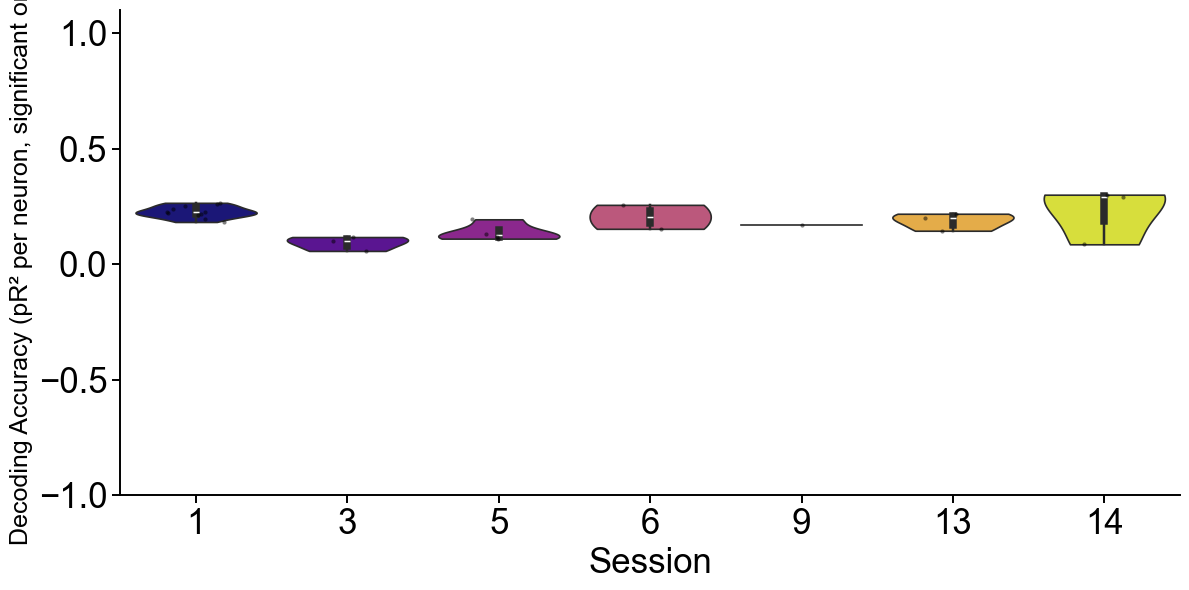

Saved summary violin: /Users/nmt121/Desktop/GLM_FORCE_pR2_violin_SIGONLY_perNEURON_bin100ms.pdf


In [89]:
from functions_experimental_data_Bräckleinexp.GLM_analysis_force_pred import *
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, re, os, pickle

# --- config ---
folder_path = '/Users/nmt121/Desktop/DATA/S1/'; session_files = session_files1
bin_size_ms = 100
fsamp = 2048
min_total_spikes_per_fold = 10
n_splits_cv = 10
save_dir = '/Users/nmt121/Desktop/'; example_dir = os.path.join(save_dir,'examples'); os.makedirs(example_dir, exist_ok=True)

# --- helpers (same goodies as spikes) ---
def choose_target_mass(y):
    p = np.mean(np.asarray(y) > 0)
    if p < 0.01: tm0, tm1, tm2 = 0.5, 30.0, 15.0
    elif p < 0.03: tm0, tm1, tm2 = 0.5, 20.0, 10.0
    elif p < 0.06: tm0, tm1, tm2 = 0.7, 14.0, 7.0
    else: tm0, tm1, tm2 = 1.0, 8.0, 4.0
    return (tm0, tm1, tm2)

def make_weights(y, cap=200.0, normalize=True):
    y = np.asarray(y).astype(int); tm0, tm1, tm2 = choose_target_mass(y)
    n0 = int((y==0).sum()); n1 = int((y==1).sum()); n2 = int((y==2).sum())
    w0 = tm0/max(n0,1); w1 = tm1/max(n1,1) if n1>0 else cap; w2 = tm2/max(n2,1) if n2>0 else cap
    w = np.ones_like(y,float); w[y==0]=np.clip(w0,1.0/cap,cap); w[y==1]=np.clip(w1,1.0/cap,cap); w[y==2]=np.clip(w2,1.0/cap,cap)
    if normalize:
        s = float(w.sum())
        if s>0 and np.isfinite(s): w *= (len(w)/s)
    return w

def _ll_poisson(y, lam): lam = np.clip(np.asarray(lam,float),1e-12,None); y = np.asarray(y,float); return float(np.sum(y*np.log(lam)-lam))
def compute_pR2_vec(y_true, y_pred):
    y_true = np.asarray(y_true,float); mu = np.clip(np.asarray(y_pred,float),1e-12,None); mu0 = np.full_like(y_true,max(y_true.mean(),1e-12))
    ll_m = _ll_poisson(y_true,mu); ll_0 = _ll_poisson(y_true,mu0); ll_sat = _ll_poisson(y_true,np.clip(y_true,1e-12,None)); denom = ll_sat-ll_0
    return np.nan if (not np.isfinite(denom) or denom<=0) else float(np.clip((ll_m-ll_0)/denom,-1.0,1.0))

def bootstrap_ci_vector(y_true, y_pred, n_iter=500, alpha=0.05, rng=0):
    rng = np.random.default_rng(rng); T=len(y_true); pr2s=np.empty(n_iter,float)
    for k in range(n_iter): idx=rng.integers(0,T,T); pr2s[k]=compute_pR2_vec(y_true[idx],y_pred[idx])
    lo=float(np.nanpercentile(pr2s,100.0*(alpha/2.0))); hi=float(np.nanpercentile(pr2s,100.0*(1.0-alpha/2.0))); return float(np.nanmean(pr2s)),lo,hi

def clip_counts(y, cap=5): return np.minimum(np.asarray(y,int), cap)

# --- your force preprocessor (unchanged) ---
def preprocess_trial_force(file, folder_path, bin_size_ms, fsamp=2048):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f: data = pickle.load(f)
    force = np.array(data['Force']); 
    if force.ndim == 2: force = force.squeeze()
    data_MU = np.array(data['MU'].tolist())
    bin_size_samples = int(bin_size_ms * fsamp / 1000)
    num_timepoints = force.shape[0]; num_bins = num_timepoints // bin_size_samples
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, num_bins * bin_size_samples, bin_size_samples), axis=1)
    binned_force = np.add.reduceat(force[:num_bins * bin_size_samples], np.arange(0, num_bins * bin_size_samples, bin_size_samples)) / bin_size_samples
    mnpair = data['Idx_MU_Pair'].tolist()
    return binned_spikes, binned_force, mnpair

# --- MAIN (force → spikes, same flow as spikes code) ---
session_sig_pr2 = {}

for session, pkl_files in session_files.items():
    spike_trials, force_trials = [], []
    for file in pkl_files:
        spikes, force, mnpair = preprocess_trial_force(file, folder_path, bin_size_ms, fsamp); 
        if spikes is None or force is None: continue
        spike_trials.append(spikes); force_trials.append(force)
    if not spike_trials or not force_trials: continue

    concatenated_spikes = np.hstack(spike_trials)               # (neurons, total_T)
    concatenated_force  = np.concatenate(force_trials, axis=0)  # (total_T,)
    num_neurons = int(concatenated_spikes.shape[0])
    outer_kf = KFold(n_splits=n_splits_cv, shuffle=True, random_state=42)
    session_sig_pr2[session] = []; print(f"Session {session}: start; neurons={num_neurons}")

    for neuron_idx in range(num_neurons):
        neuron_spikes = concatenated_spikes[neuron_idx,:]
        X_full, Y_full = create_force_glm_data(concatenated_force, neuron_spikes)  # your helper builds the force design + target spikes
        if X_full is None or Y_full is None: continue
        if not np.all(np.isfinite(X_full)) or not np.all(np.isfinite(Y_full)):
            good = np.isfinite(Y_full)
            for j in range(X_full.shape[1]): good &= np.isfinite(X_full[:,j])
            X_full, Y_full = X_full[good], Y_full[good]
        if np.sum(Y_full) < min_total_spikes_per_fold: continue

        ll_m_sum = 0.0; ll_sat_sum = 0.0; total_y = 0.0; total_n = 0
        y_true_all, y_pred_all = [], []
        i = 0

        for tr_idx, te_idx in outer_kf.split(X_full):
            i += 1
            X_tr, X_te = X_full[tr_idx], X_full[te_idx]; Y_tr, Y_te = Y_full[tr_idx], Y_full[te_idx]
            if np.sum(Y_te) < min_total_spikes_per_fold: continue

            w_tr = make_weights(Y_tr, cap=200.0, normalize=True); Y_tr_clip = clip_counts(Y_tr, cap=5)

            mdl_hgb = HistGradientBoostingRegressor(loss="poisson", learning_rate=0.06, max_iter=1000, max_depth=3, min_samples_leaf=30, l2_regularization=0.1, early_stopping=True, validation_fraction=0.1, random_state=42)
            mdl_lin = PoissonRegressor(alpha=1.0, max_iter=3000, fit_intercept=True, tol=1e-6, warm_start=False)

            try:
                mdl_hgb.fit(X_tr, Y_tr_clip, sample_weight=w_tr); pred_hgb = np.clip(mdl_hgb.predict(X_te), 1e-12, None); pr2_hgb = compute_pR2_vec(Y_te, pred_hgb)
            except Exception as e:
                pred_hgb = None; pr2_hgb = -1e9
            try:
                scaler = StandardScaler(); X_tr_s = scaler.fit_transform(X_tr); X_te_s = scaler.transform(X_te); mdl_lin.fit(X_tr_s, Y_tr_clip, sample_weight=w_tr); pred_lin = np.clip(mdl_lin.predict(X_te_s), 1e-12, None); pr2_lin = compute_pR2_vec(Y_te, pred_lin)
            except Exception as e:
                pred_lin = None; pr2_lin = -1e9

            y_pred = pred_hgb if (pr2_hgb >= pr2_lin and pred_hgb is not None) else pred_lin if pred_lin is not None else np.full_like(Y_te, max(Y_te.mean(),1e-12))

            ll_m_sum += _ll_poisson(Y_te, y_pred); ll_sat_sum += _ll_poisson(Y_te, np.clip(Y_te,1e-12,None)); total_y += float(Y_te.sum()); total_n += int(Y_te.shape[0])
            y_true_all.append(Y_te); y_pred_all.append(y_pred)

            if neuron_idx == 1 and session == list(session_files.keys())[0]:
                plt.figure(figsize=(12,4)); plt.plot(Y_te, label="True spikes (binned)", color="black"); plt.plot(y_pred, label="Predicted intensity", color="red"); plt.xlabel("Time bins"); plt.ylabel("Spike count"); plt.title(f"Force→Spikes | Neuron {neuron_idx} | Session {session} | Fold {i}"); plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(example_dir, f"{session}_force2spikes_neuron{neuron_idx}_fold{i}_bin{bin_size_ms}ms.pdf"), dpi=300, bbox_inches='tight'); plt.close()

        if total_n == 0: continue
        mu0 = max(total_y/total_n, 1e-12); ll0_total = total_y*np.log(mu0) - total_n*mu0; denom = ll_sat_sum - ll0_total
        pr2_neuron = np.nan if (not np.isfinite(denom) or denom<=0) else float(np.clip((ll_m_sum - ll0_total)/denom, -1.0, 1.0))

        y_true_cat = np.concatenate(y_true_all, axis=0); y_pred_cat = np.concatenate(y_pred_all, axis=0)
        b_mean, b_lo, b_hi = bootstrap_ci_vector(y_true_cat, y_pred_cat, n_iter=500, alpha=0.05, rng=123 + neuron_idx)
        if b_lo > 0: session_sig_pr2[session].append(pr2_neuron)

    print(f"Session {session}: kept {len(session_sig_pr2[session])} significant neurons")

# --- violin of significant neurons only ---
plt.figure(figsize=(12,6)); plt.rcParams.update({'font.family':'Arial'})
all_pR2s, all_labels = [], []
for session, vals in session_sig_pr2.items():
    if len(vals)==0: continue
    m = re.search(r'(\d+)', session); lab = str(int(m.group(1))) if m else session
    all_pR2s.extend(vals); all_labels.extend([lab]*len(vals))
if len(all_pR2s)==0: print("No significant neurons found (CI lower bound ≤ 0)."); all_pR2s=[0.0]; all_labels=["none"]
unique_labels = sorted(set(all_labels), key=lambda x:int(x)) if all_labels!=["none"] else ["none"]
N = max(2,len(unique_labels)); cmap = plt.get_cmap('plasma'); colors = [cmap(i/(N-1)) for i in range(N)]; palette_dict = dict(zip(unique_labels, colors))
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0); sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)
ax = plt.gca()
for s in ax.spines.values(): s.set_linewidth(1.4)
plt.tick_params(width=1.4, length=6, labelsize=25); plt.xlabel("Session", fontsize=25, fontname="Arial"); plt.ylabel("Decoding Accuracy (pR² per neuron, significant only)", fontsize=18, fontname="Arial"); plt.ylim([-1,1.1]); sns.despine(top=True,right=True); plt.tight_layout()
out_path = os.path.join(save_dir, f"GLM_FORCE_pR2_violin_SIGONLY_perNEURON_bin{bin_size_ms}ms.pdf"); plt.savefig(out_path, dpi=300, bbox_inches='tight'); plt.show(); print("Saved summary violin:", out_path)
